In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams['figure.figsize'] = (12,8)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 12

In [2]:
G = nx.read_edgelist('graph.edgelist')

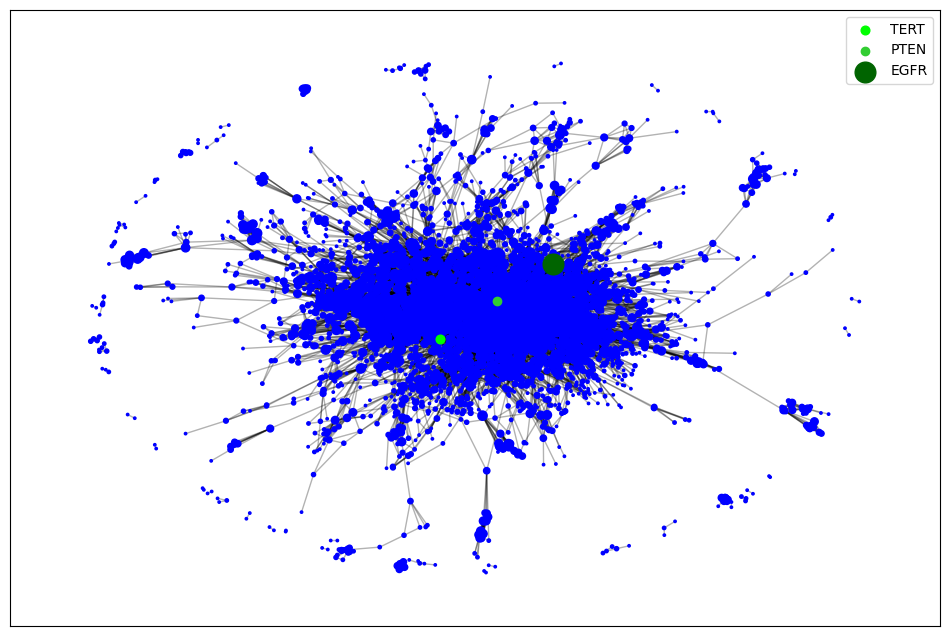

In [3]:
sementes = ['TERT', 'PTEN', 'EGFR']
sem_sementes = list(set(G.nodes) - set(sementes))
cores = ['lime', 'limegreen', 'darkgreen']
pos_iniciais = {no: (0+i*10, 0+i*10) for i, no in enumerate(sementes)}

pos = nx.spring_layout(G, pos=pos_iniciais, fixed=sementes, seed=42, k=0.8)

for semente, cor in list(zip(sementes, cores)):
    nx.draw_networkx_nodes(G, pos, nodelist=[semente], node_color=cor, node_size=G.degree(semente)*3, label=semente).set_zorder(3)

nx.draw_networkx_edges(G, pos, alpha=0.3)
nx.draw_networkx_nodes(G, pos, nodelist=sem_sementes, node_color='blue', node_size=list(map(lambda x: x[1]*3, G.degree(sem_sementes))))

plt.legend()
plt.savefig("grafo_customizado.png", format="PNG", dpi=300)

plt.show()

### Estrutura da rede

In [7]:
print('Número de vértices: ', G.number_of_nodes())
print('Número de arestas: ', G.number_of_edges())
if not nx.is_connected(G):
    print('Número de componentes conectadas: ', nx.number_connected_components(G))
    print('Número de isolados: ', len(list(nx.isolates(G))))
else:
    print('Rede conectada: Sim')

largest_component_nodes = max(nx.connected_components(G), key=len)
G = G.subgraph(largest_component_nodes).copy()

print('Novo número de vértices (maior componente conectada): ', G.number_of_nodes())
print('Novo número de arestas (maior componente conectada): ', G.number_of_edges())

Número de vértices:  4425
Número de arestas:  15516
Número de componentes conectadas:  53
Número de isolados:  0
Novo número de vértices (maior componente conectada):  4237
Novo número de arestas (maior componente conectada):  15255


## Métricas globais

Densidade:  0.002


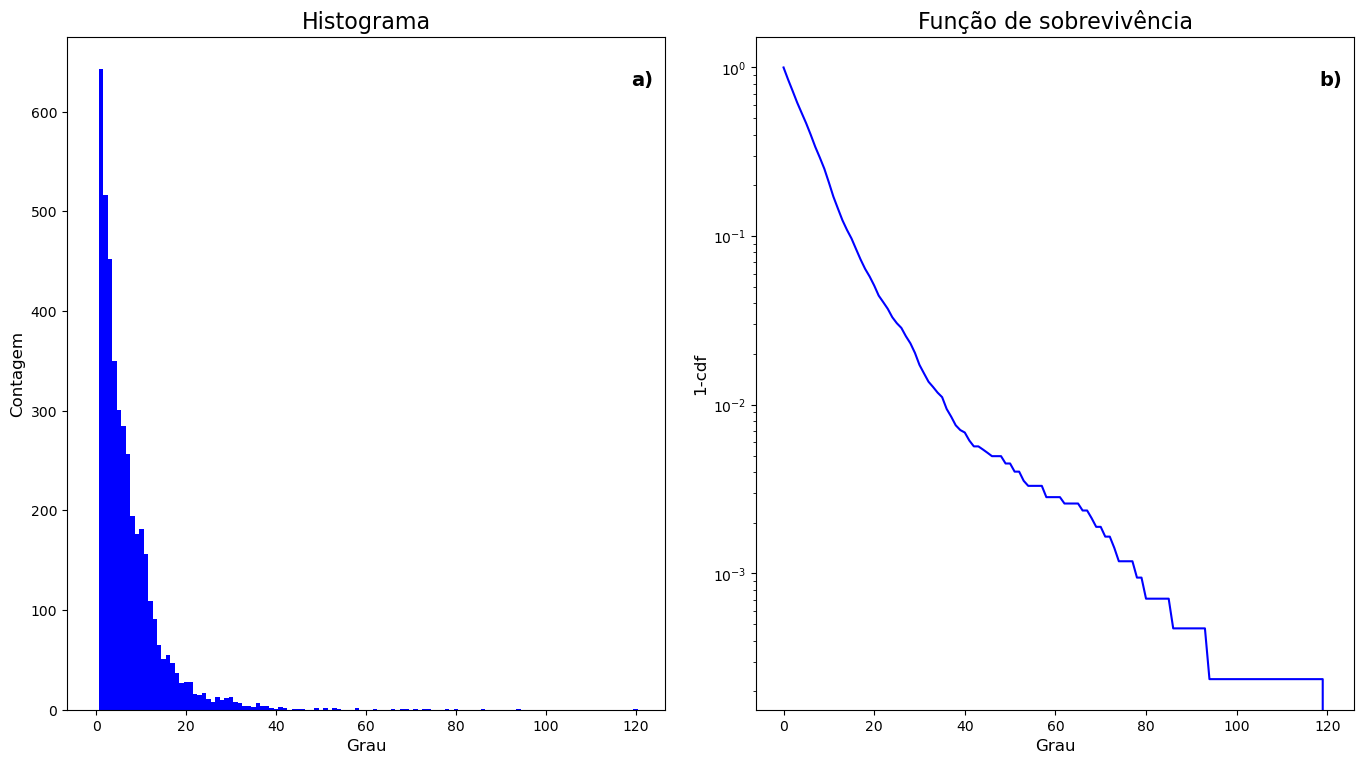

In [8]:
print(f'Densidade: {nx.density(G): .3f}')
fig, axs = plt.subplots(1,2, figsize=(14,8))

hist = nx.degree_histogram(G)
degrees = np.array(range(len(hist)))

axs[0].bar(degrees, hist, color='blue', width=1.0)
axs[0].set_title('Histograma')
axs[0].set_xlabel('Grau')
axs[0].set_ylabel('Contagem')
axs[0].text(0.98, 0.95, 'a)', 
        transform=axs[0].transAxes, 
        va='top', ha='right', 
        fontsize=14,
        fontweight='bold')
cumhist = 1-np.cumsum(hist)/np.sum(hist)
axs[1].semilogy(degrees, cumhist, color='blue')
axs[1].set_title('Função de sobrevivência')
axs[1].set_xlabel('Grau')
axs[1].set_ylabel('1-cdf')
axs[1].text(0.98, 0.95, 'b)', 
        transform=axs[1].transAxes, 
        va='top', ha='right', 
        fontsize=14,
        fontweight='bold')

plt.tight_layout(pad=2)
plt.savefig('dist_graus.png',format="PNG", dpi=300)
plt.show()

**Diâmetro:** Definido pela maior excentricidade entre todos os vértices

**Raio:** Definido pela menor excentricidade entre todos os vértices

In [9]:
print(f'Diâmetro: {nx.diameter(G):.3f}')
print(f'Raio: {nx.radius(G):.3f}')

Diâmetro: 17.000
Raio: 9.000


In [10]:
n = nx.number_of_nodes(G)
nos = list(G.nodes)
dist_matrix = np.full((n, n), np.inf)
np.fill_diagonal(dist_matrix, 0)

for origem, dist in nx.all_pairs_shortest_path_length(G):
    for destino, comprimento in dist.items():
        pos_origem = nos.index(origem)
        pos_destino = nos.index(destino)
        dist_matrix[pos_origem][pos_destino] = comprimento

comprimentos_validos = dist_matrix[(dist_matrix > 0) & (dist_matrix < np.inf)]

plt.hist(comprimentos_validos, bins=15)

#plt.title('Distribuição dos Comprimentos de Caminhos Mais Curtos')
plt.xlabel('Comprimento')
plt.ylabel('Frequência')
plt.grid(axis='y', alpha=0.3)
plt.savefig('dist_min_paths.png', format="PNG", dpi=300)

plt.show()

KeyboardInterrupt: 

In [11]:
print(f'Coesão/Agrupamento: {nx.transitivity(G): .3f}')

Coesão/Agrupamento:  0.284


In [12]:
sorted(G.degree(), key=lambda x:x[1])[::-1]

[('TP53', 120),
 ('CTNNB1', 94),
 ('FN1', 86),
 ('CD4', 80),
 ('HDAC1', 78),
 ('EGFR', 74),
 ('CD44', 73),
 ('SRC', 71),
 ('HSP90AA1', 69),
 ('EP300', 68),
 ('AKT1', 66),
 ('GRB2', 62),
 ('CDC42', 58),
 ('HSP90AB1', 58),
 ('TRAF6', 54),
 ('CD8A', 53),
 ('BRCA1', 53),
 ('CALM3', 51),
 ('TLR4', 51),
 ('DLG4', 49),
 ('HSPA4', 49),
 ('TNF', 46),
 ('MYD88', 45),
 ('ATM', 44),
 ('TJP1', 42),
 ('CALML3', 42),
 ('EGF', 41),
 ('CALML5', 41),
 ('STAT3', 41),
 ('ESR1', 40),
 ('PXN', 39),
 ('H3C12', 39),
 ('STAT1', 38),
 ('HDAC2', 38),
 ('MYC', 38),
 ('CALML6', 38),
 ('IFNG', 37),
 ('IL1B', 37),
 ('VCL', 37),
 ('CALML4', 37),
 ('RBX1', 36),
 ('RAD51', 36),
 ('JUN', 36),
 ('SMAD3', 36),
 ('BCL2', 36),
 ('TLR2', 36),
 ('NCOR1', 36),
 ('APP', 35),
 ('H3C13', 35),
 ('H3-3B', 35),
 ('IL2', 34),
 ('JAK1', 34),
 ('RIPK1', 34),
 ('ICAM1', 34),
 ('CTLA4', 33),
 ('ITGB1', 33),
 ('FYN', 33),
 ('RHOA', 33),
 ('CD19', 32),
 ('SHC1', 32),
 ('BECN1', 32),
 ('CDK2', 32),
 ('LRP5', 32),
 ('DVL1', 32),
 ('CREBBP', 